# EN3160 Assignment 3: Neural Networks
**Name:** Hiviru Hansitha Palihena  
**Index Number:** 230458P  

## Part 1: One Layer Dense Network Modification

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Verify PyTorch installation and device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


### 1. Dataloading and Parameter Initialization

The CIFAR-10 dataset is loaded and normalized here, alongside the parameter initialization for our two-layer dense network. Rather than mapping the 3072 input features directly to the 10 output classes, the architecture introduces an intermediate hidden layer with 100 nodes (`H = 100`). Weights and biases for both the hidden layer ($W_1, b_1$) and the output layer ($W_2, b_2$) are initialized with scaled random values and moved to the GPU.

In [2]:
# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (3072)
H = 100            # Hidden layer size (NEW)
K = 10             # Output size (10 classes)

# Initialize weights and biases (moved to GPU using .to(device))
# Layer 1: Input to Hidden
w1 = torch.randn(Din, H, device=device) * (1.0 / (Din ** 0.5)) 
b1 = torch.zeros(H, device=device)

# Layer 2: Hidden to Output
w2 = torch.randn(H, K, device=device) * (1.0 / (H ** 0.5))
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10  # Changed to 10 epochs as per assignment requirements
lr = 1e-1    # Adjusted learning rate for cross-entropy and sigmoid
lr_decay = 0.9
reg = 0.001
loss_history = []

Files already downloaded and verified
Files already downloaded and verified


### 2. Training Loop: Forward Pass, Cross-Entropy Loss, and Backpropagation

In the forward pass, the flattened input vectors first pass through the hidden layer ($z_1 = x W_1 + b_1$) followed by a sigmoid activation function ($h_1 = \sigma(z_1) = \frac{1}{1 + e^{-z_1}}$). The resulting 100-dimensional hidden representations are then projected to the 10 output classes via the second linear layer ($z_2 = h_1 W_2 + b_2$). These output logits are converted into class probabilities using the softmax function, and the error is evaluated using categorical cross-entropy loss with $L_2$ regularization. During backpropagation, gradients are computed manually using the chain rule: starting from the output layer's softmax cross-entropy derivative ($\frac{\partial L}{\partial z_2} = \frac{1}{N}(\hat{y} - y)$) to find $\nabla W_2$ and $\nabla b_2$, and then propagating the error backward through $W_2^T$ and the sigmoid derivative ($\sigma(z_1)(1 - \sigma(z_1))$) to update $W_1$ and $b_1$ over 10 epochs.

Epoch 1/10, Loss: 1.8770
Epoch 2/10, Loss: 1.7501
Epoch 3/10, Loss: 1.7006
Epoch 4/10, Loss: 1.6653
Epoch 5/10, Loss: 1.6361
Epoch 6/10, Loss: 1.6128
Epoch 7/10, Loss: 1.5921
Epoch 8/10, Loss: 1.5749
Epoch 9/10, Loss: 1.5600
Epoch 10/10, Loss: 1.5470


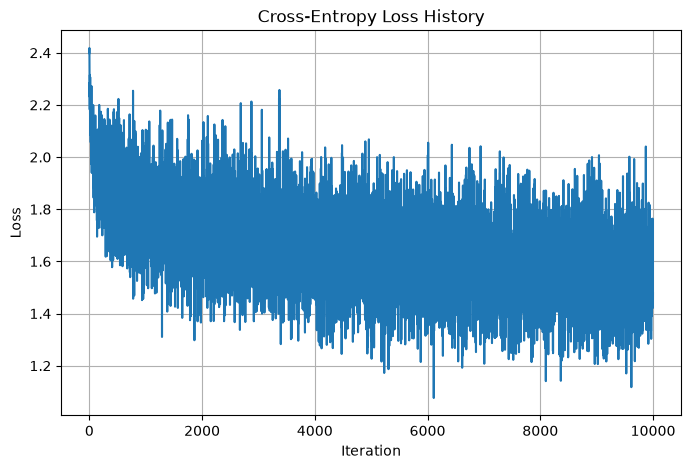

In [3]:
# 3. Training Loop
for t in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels and move to GPU
        inputs, labels = data[0].to(device), data[1].to(device)
        
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot
        
        # --- Forward Pass ---
        # Layer 1: Input to Hidden (with Sigmoid activation)
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)  # Shape: (Ntr, H)
        
        # Layer 2: Hidden to Output (Logits)
        z2 = h1.mm(w2) + b2     # Shape: (Ntr, K)
        
        # Softmax probabilities (shifted by max for numerical stability)
        z2_shifted = z2 - torch.max(z2, dim=1, keepdim=True)[0]
        exp_scores = torch.exp(z2_shifted)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        
        # --- Cross-Entropy Loss Calculation (with L2 regularization) ---
        # Add 1e-8 inside log to prevent log(0)
        core_loss = -torch.sum(y_train_onehot * torch.log(probs + 1e-8)) / Ntr
        reg_loss = 0.5 * reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss = core_loss + reg_loss
        
        loss_history.append(loss.item())
        running_loss += loss.item()
        
        # --- Backpropagation ---
        # Gradient at output layer (Cross-Entropy + Softmax derivative)
        dz2 = (probs - y_train_onehot) / Ntr  # Shape: (Ntr, K)
        
        # Gradients for w2 and b2
        dw2 = h1.t().mm(dz2) + reg * w2
        db2 = dz2.sum(dim=0)
        
        # Backpropagate to hidden layer
        dh1 = dz2.mm(w2.t())  # Shape: (Ntr, H)
        
        # Gradient through Sigmoid activation: h1 * (1 - h1)
        dz1 = dh1 * (h1 * (1.0 - h1))  # Shape: (Ntr, H)
        
        # Gradients for w1 and b1
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)
        
        # --- Parameter Update ---
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print average loss for every epoch
    print(f"Epoch {t+1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")
    
    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Cross-Entropy Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

#### 3. Model Evaluation: Training and Test Accuracies

After training for 10 epochs, the network is evaluated on both the training and test partitions of the CIFAR-10 dataset with gradient tracking disabled (`torch.no_grad()`). The forward pass is updated to route the flattened inputs through the hidden layer with the sigmoid activation before computing the final output logits ($z_2 = \sigma(x W_1 + b_1) W_2 + b_2$). Since the softmax function is monotonically increasing, `torch.argmax` can be applied directly to the raw output logits $z_2$ to determine the predicted class indices and compute the overall classification accuracy.

In [5]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        
        # Forward pass through both layers
        h1_train = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h1_train.mm(w2) + b2
        
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data[0].to(device), data[1].to(device)
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        
        # Forward pass through both layers
        h1_test = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h1_test.mm(w2) + b2
        
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Training accuracy: 51.27%
Test accuracy: 47.45%
